In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

In [8]:
df=pd.read_csv(r"C:\pythonfullstack\project\EEG PROJECT\DATA\synthetic_eeg_data-v3.csv",encoding="latin1")
df

,no.,sex,age,eeg.date,education,IQ,EQ,disorder/diagnosis,EEG_Electrode_1,EEG_Electrode_2,...,EEG_Electrode_23,EEG_Electrode_24,EEG_Electrode_25,EEG_Electrode_26,EEG_Electrode_27,EEG_Electrode_28,EEG_Electrode_29,EEG_Electrode_30,EEG_Electrode_31,EEG_Electrode_32
0,1,F,28,2024-10-31,High School,124,99,Parkinson,"[0.33455714134489933, -1.0124825404627846, 0.4...","[-0.49712810877710073, -1.181443147283427, -0....",...,"[-1.99740458536635, 1.1675142221161818, -1.114...","[1.7731558286269427, -0.8660494297910852, 0.65...","[-0.2391043711434249, -1.5441592677029112, -0....","[0.1587242362378963, 0.7578533521985614, -1.46...","[0.6316355991945747, -0.3678480270031867, -1.3...","[-1.4444667012235493, 2.2621772753996514, -0.5...","[0.15387878503907995, -0.10853770234891194, -0...","[0.3154781284463222, 0.9463885574242941, 1.099...","[0.5526415164712162, -0.2544903680359615, -2.0...","[1.0021452006377516, 0.3729396954838123, -0.74..."
1,2,F,18,2024-06-07,University,98,108,Depressive disorder,"[-0.02739863367216427, -2.1875200427753687, -0...","[-1.6063495702382038, -1.9489607776118076, -0....",...,"[0.6887557986518217, -0.3765638799484069, 0.64...","[0.9580020402801734, 0.11347676004067732, -1.0...","[-0.5657130138418595, -0.4364533687176666, 0.0...","[-0.22115579682549202, 1.485179632951922, 0.43...","[1.2361833741288593, -0.4357165426202037, 1.40...","[-0.3686085024420043, -0.10918331805000155, -0...","[0.2726137476493269, -0.008248258578368504, 1....","[0.26342122129676815, 1.8219102244040832, -0.8...","[-0.8784199632117726, -0.5760279509082266, 1.0...","[0.45690822319584296, -2.4112525822450555, -2...."
2,3,M,59,2024-06-23,High School,123,157,Bipolar disorder,"[1.0050013043908792, 1.6817611285088891, -0.02...","[-1.0385591774086103, 1.2250956787566445, 0.83...",...,"[-1.1199358297465518, -1.850280760207885, 0.86...","[0.8814568522541026, 0.293235902200372, 0.3036...","[1.7617998892464164, -0.2746956613556493, 1.65...","[-0.23674162770929155, -1.9493936103275236, -0...","[-0.7963995959246195, -0.15201814117080004, 1....","[-0.563035007550588, 0.16101140922425464, 0.07...","[0.5750813115048556, -0.3098870800966042, 0.75...","[-0.2076793528753609, -0.24468906421486908, 0....","[-0.856616999041279, 0.3935970670401432, 0.542...","[0.07681096961593926, 0.768816229114708, -0.59..."
3,4,F,19,2024-06-20,High School,93,116,Psychopathy,"[-0.43027103554325313, -0.9495404173994122, 0....","[-0.3237876606542493, 0.7128845452767104, 0.03...",...,"[0.04156590423560202, 0.42027620630613444, 0.8...","[0.3055015728242051, 0.9390547474946099, 0.201...","[0.5588089727285818, -0.17132871262269428, -0....","[-1.983526303150428, -0.45274813775690154, 0.3...","[0.5019664433487486, -0.8938051132944905, -1.2...","[1.458871854920239, 0.12823682600076106, 1.503...","[-1.1090947792585244, -0.34756725922122883, -0...","[-0.7097904204884279, -0.5647292673395053, 0.3...","[-0.03142591776844011, -1.677637114372979, -1....","[0.5916353841295418, 0.7115851187328803, -0.57..."
4,5,F,29,2025-01-03,University,101,51,MS,"[1.5543439569608053, 2.2785650194030707, -3.20...","[-0.66726833185029, 0.7585408377070836, -0.303...",...,"[0.5264386679561065, -0.6702393228821288, 0.76...","[-0.07186336169811193, -0.9981504586508025, 0....","[-0.638747287207778, -0.6485048304469717, 1.98...","[-1.4719549650034853, 0.838684896631107, 0.555...","[0.6968676602358026, -0.3788571056047837, -0.0...","[-1.4804857637591342, -2.3024773024616936, 1.3...","[1.9173791176876227, -1.10512256096403, 1.2654...","[-0.5355393638751318, -0.3880278973261586, -1....","[0.2294584405683268, 0.9123223629271447, -1.21...","[-0.5800779808862577, 0.19416927087993818, -0...."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3439,3440,M,38,2025-03-01,High School,139,94,Obsessive compulsive disorder,"[1.5467644977632347, 1.7425617757574132, -0.71...","[-0.6731899343891082, 0.17122170014803612, -0....",...,"[0.26288016198230424, 0.47772351583489686, -0....","[-0.7956549944391

In [9]:
df.isnull().sum()

no.                   0
sex                   0
age                   0
eeg.date              0
education             0
IQ                    0
EQ                    0
disorder/diagnosis    0
EEG_Electrode_1       0
EEG_Electrode_2       0
EEG_Electrode_3       0
EEG_Electrode_4       0
EEG_Electrode_5       0
EEG_Electrode_6       0
EEG_Electrode_7       0
EEG_Electrode_8       0
EEG_Electrode_9       0
EEG_Electrode_10      0
EEG_Electrode_11      0
EEG_Electrode_12      0
EEG_Electrode_13      0
EEG_Electrode_14      0
EEG_Electrode_15      0
EEG_Electrode_16      0
EEG_Electrode_17      0
EEG_Electrode_18      0
EEG_Electrode_19      0
EEG_Electrode_20      0
EEG_Electrode_21      0
EEG_Electrode_22      0
EEG_Electrode_23      0
EEG_Electrode_24      0
EEG_Electrode_25      0
EEG_Electrode_26      0
EEG_Electrode_27      0
EEG_Electrode_28      0
EEG_Electrode_29      0
EEG_Electrode_30      0
EEG_Electrode_31      0
EEG_Electrode_32      0
dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3444 entries, 0 to 3443
Data columns (total 40 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   no.                 3444 non-null   int64 
 1   sex                 3444 non-null   object
 2   age                 3444 non-null   int64 
 3   eeg.date            3444 non-null   object
 4   education           3444 non-null   object
 5   IQ                  3444 non-null   int64 
 6   EQ                  3444 non-null   int64 
 7   disorder/diagnosis  3444 non-null   object
 8   EEG_Electrode_1     3444 non-null   object
 9   EEG_Electrode_2     3444 non-null   object
 10  EEG_Electrode_3     3444 non-null   object
 11  EEG_Electrode_4     3444 non-null   object
 12  EEG_Electrode_5     3444 non-null   object
 13  EEG_Electrode_6     3444 non-null   object
 14  EEG_Electrode_7     3444 non-null   object
 15  EEG_Electrode_8     3444 non-null   object
 16  EEG_Electrode_9     3444

In [11]:
print("row",df.shape[0])
print("columns:",df.shape[1])
# print(df.shape)

row 3444
columns: 40


In [12]:
df.columns

Index(['no.', 'sex', 'age', 'eeg.date', 'education', 'IQ', 'EQ',
       'disorder/diagnosis', 'EEG_Electrode_1', 'EEG_Electrode_2',
       'EEG_Electrode_3', 'EEG_Electrode_4', 'EEG_Electrode_5',
       'EEG_Electrode_6', 'EEG_Electrode_7', 'EEG_Electrode_8',
       'EEG_Electrode_9', 'EEG_Electrode_10', 'EEG_Electrode_11',
       'EEG_Electrode_12', 'EEG_Electrode_13', 'EEG_Electrode_14',
       'EEG_Electrode_15', 'EEG_Electrode_16', 'EEG_Electrode_17',
       'EEG_Electrode_18', 'EEG_Electrode_19', 'EEG_Electrode_20',
       'EEG_Electrode_21', 'EEG_Electrode_22', 'EEG_Electrode_23',
       'EEG_Electrode_24', 'EEG_Electrode_25', 'EEG_Electrode_26',
       'EEG_Electrode_27', 'EEG_Electrode_28', 'EEG_Electrode_29',
       'EEG_Electrode_30', 'EEG_Electrode_31', 'EEG_Electrode_32'],
      dtype='object')

In [13]:
df.duplicated().sum()

0

In [14]:
target="disorder/diagnosis"
print("number of clases:",df[target].nunique())
print("\nclasses:")
df[target].unique()

number of clases: 16

classes:


array(['Parkinson', 'Depressive disorder', 'Bipolar disorder',
       'Psychopathy', 'MS', 'Panic disorder', 'Alcohol use disorder',
       'Obsessive compulsive disorder', 'Alzheimer',
       'Borderline personality disorder', 'PTSD',
       'Behavioral addiction disorder', 'Social anxiety disorder',
       'Asperger', 'ADHD', 'Schizophrenia'], dtype=object)

In [15]:
df[target].value_counts()

Borderline personality disorder    240
Behavioral addiction disorder      237
Alcohol use disorder               230
Panic disorder                     222
Alzheimer                          221
Bipolar disorder                   216
Parkinson                          215
PTSD                               213
Social anxiety disorder            213
Psychopathy                        212
Schizophrenia                      211
Asperger                           207
Obsessive compulsive disorder      206
ADHD                               203
MS                                 200
Depressive disorder                198
Name: disorder/diagnosis, dtype: int64

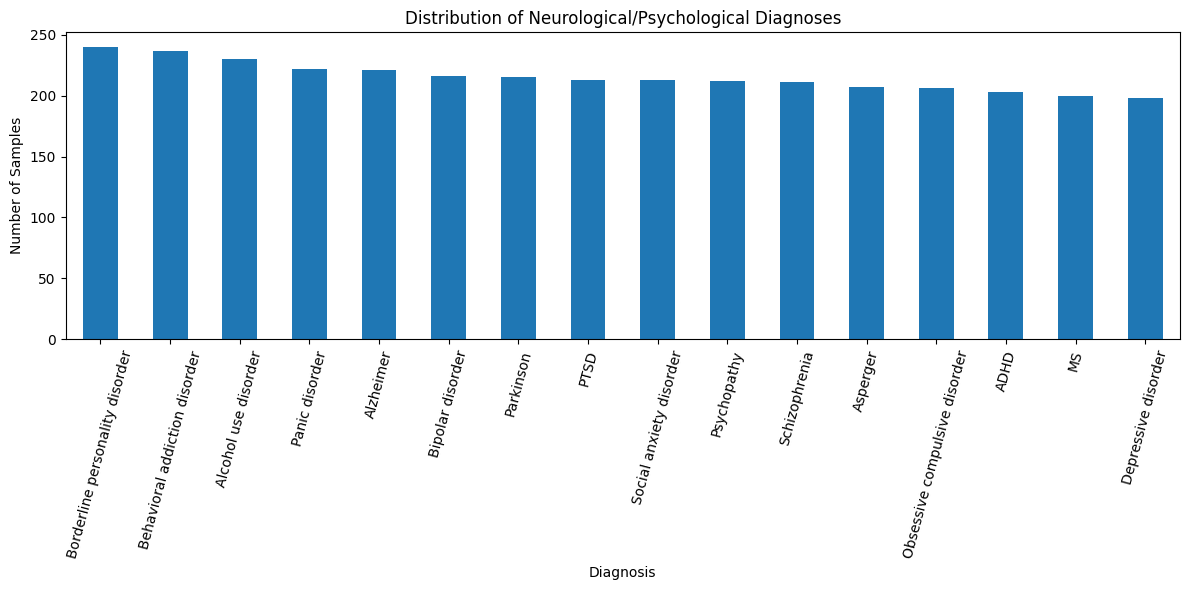

In [16]:
plt.figure(figsize=(12, 6))

df[target].value_counts().plot(kind="bar")

plt.title("Distribution of Neurological/Psychological Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [17]:
eeg_columns = [
    col for col in df.columns
    if col.startswith("EEG_Electrode_")
]

print("Number of EEG electrodes:", len(eeg_columns))
print(eeg_columns)

Number of EEG electrodes: 32
['EEG_Electrode_1', 'EEG_Electrode_2', 'EEG_Electrode_3', 'EEG_Electrode_4', 'EEG_Electrode_5', 'EEG_Electrode_6', 'EEG_Electrode_7', 'EEG_Electrode_8', 'EEG_Electrode_9', 'EEG_Electrode_10', 'EEG_Electrode_11', 'EEG_Electrode_12', 'EEG_Electrode_13', 'EEG_Electrode_14', 'EEG_Electrode_15', 'EEG_Electrode_16', 'EEG_Electrode_17', 'EEG_Electrode_18', 'EEG_Electrode_19', 'EEG_Electrode_20', 'EEG_Electrode_21', 'EEG_Electrode_22', 'EEG_Electrode_23', 'EEG_Electrode_24', 'EEG_Electrode_25', 'EEG_Electrode_26', 'EEG_Electrode_27', 'EEG_Electrode_28', 'EEG_Electrode_29', 'EEG_Electrode_30', 'EEG_Electrode_31', 'EEG_Electrode_32']


In [18]:
print(type(df["EEG_Electrode_1"].iloc[0]))
print(df["EEG_Electrode_1"].iloc[0])

<class 'str'>
[0.33455714134489933, -1.0124825404627846, 0.4246444374579689, -0.39079455915845135, 0.015675295969336464, -0.17008935539276962, 1.3103796649322375, 0.5960890323585392, 0.26686898509269263, -0.3869912181543485, 1.6710548124177231, 0.07641493023775006, -0.8655086018876715, -0.5049869868051015, -0.3779361418958152, -0.22063312138975053, -0.4599822143016219, 0.3553842558070888, 0.0008691107500319095, 0.6610521252737255, -0.6213901191159426, -0.26049714525216955, 0.7852869419031999, 0.018827785604311077, -0.7341763540781039, -0.11908837299695473, 0.04039845791283804, -1.6531652200216367, 1.0177926115864762, -0.884310564410691, 0.26894695030049365, -0.5339995289454661, 0.39297612833065343, -1.518636567425502, -0.05765945586193, 0.13046451162706138, -0.1049848836237919, -0.5531792561320441, 0.6149248115366365, 0.2762926232488689, 0.1796120173785568, -0.2470238526524436, -0.07919219749360527, -0.26174526015132243, -0.7246378735330332, -0.031446241782728854, 0.7836692844133004, 2

eeg signal convering


In [19]:
def convert_eeg(value):
    if isinstance(value, (list, np.ndarray)):
        return np.asarray(value, dtype=float)
    
    if isinstance(value, str):
        value = value.strip("[]")
        return np.fromstring(value, sep=",")
    
    return np.array([], dtype=float)


for col in eeg_columns:
    df[col] = df[col].apply(convert_eeg)

print("EEG signals converted successfully!")

EEG signals converted successfully!


In [20]:
signal = df["EEG_Electrode_1"].iloc[0]

print("Type:", type(signal))
print("Number of samples:", len(signal))
print("First 10 values:", signal[:10])

Type: <class 'numpy.ndarray'>
Number of samples: 256
First 10 values: [ 0.33455714 -1.01248254  0.42464444 -0.39079456  0.0156753  -0.17008936
  1.31037966  0.59608903  0.26686899 -0.38699122]


In [21]:
for col in eeg_columns:
    invalid = df[col].apply(
        lambda x: len(x) != 256 or not np.all(np.isfinite(x))
    ).sum()
    
    print(f"{col}: {invalid} invalid signals")

EEG_Electrode_1: 0 invalid signals
EEG_Electrode_2: 0 invalid signals
EEG_Electrode_3: 0 invalid signals
EEG_Electrode_4: 0 invalid signals
EEG_Electrode_5: 0 invalid signals
EEG_Electrode_6: 0 invalid signals
EEG_Electrode_7: 0 invalid signals
EEG_Electrode_8: 0 invalid signals
EEG_Electrode_9: 0 invalid signals
EEG_Electrode_10: 0 invalid signals
EEG_Electrode_11: 0 invalid signals
EEG_Electrode_12: 0 invalid signals
EEG_Electrode_13: 0 invalid signals
EEG_Electrode_14: 0 invalid signals
EEG_Electrode_15: 0 invalid signals
EEG_Electrode_16: 0 invalid signals
EEG_Electrode_17: 0 invalid signals
EEG_Electrode_18: 0 invalid signals
EEG_Electrode_19: 0 invalid signals
EEG_Electrode_20: 0 invalid signals
EEG_Electrode_21: 0 invalid signals
EEG_Electrode_22: 0 invalid signals
EEG_Electrode_23: 0 invalid signals
EEG_Electrode_24: 0 invalid signals
EEG_Electrode_25: 0 invalid signals
EEG_Electrode_26: 0 invalid signals
EEG_Electrode_27: 0 invalid signals
EEG_Electrode_28: 0 invalid signals
E

In [22]:
all_values = np.concatenate(df["EEG_Electrode_1"].values)

print("Minimum:", all_values.min())
print("Maximum:", all_values.max())
print("Mean:", all_values.mean())
print("Standard deviation:", all_values.std())

Minimum: -5.214104074352514
Maximum: 4.958403537326359
Mean: 0.0013481044440147865
Standard deviation: 0.9989909997855849


In [23]:
def normalize_signal(signal):
    signal = np.asarray(signal, dtype=float)
    
    mean = np.mean(signal)
    std = np.std(signal)
    
    if std == 0:
        return signal - mean
    
    return (signal - mean) / std

In [24]:
for col in eeg_columns:
    df[col] = df[col].apply(normalize_signal)

print("EEG normalization completed.")

EEG normalization completed.


feature extraction 

In [25]:
def extract_features(signal):
    signal = np.asarray(signal, dtype=float)

    features = {
        "mean": np.mean(signal),
        "std": np.std(signal),
        "variance": np.var(signal),
        "rms": np.sqrt(np.mean(signal ** 2)),
        "min": np.min(signal),
        "max": np.max(signal),
        "peak_to_peak": np.ptp(signal),
        "skewness": skew(signal),
        "kurtosis": kurtosis(signal),
        "zero_crossing_rate": np.mean(np.diff(np.sign(signal)) != 0)
    }

    return features

In [26]:
test_features = extract_features(df["EEG_Electrode_1"].iloc[0])

print(test_features)

{'mean': -2.0816681711721685e-17, 'std': 1.0, 'variance': 1.0, 'rms': 1.0, 'min': -2.766373782636353, 'max': 2.6366126721002607, 'peak_to_peak': 5.402986454736613, 'skewness': -0.1802537597114425, 'kurtosis': 0.12413922311686676, 'zero_crossing_rate': 0.49411764705882355}


In [27]:
feature_rows = []

for _, row in df.iterrows():
    features = {}

    for col in eeg_columns:
        electrode_features = extract_features(row[col])

        electrode_number = col.replace("EEG_Electrode_", "E")

        for feature_name, value in electrode_features.items():
            features[f"{electrode_number}_{feature_name}"] = value

    features["diagnosis"] = row["disorder/diagnosis"]

    feature_rows.append(features)

features_df = pd.DataFrame(feature_rows)

print("Feature extraction completed!")
print("Shape:", features_df.shape)

Feature extraction completed!
Shape: (3444, 321)


In [28]:
features_df.head()

,E1_mean,E1_std,E1_variance,E1_rms,E1_min,E1_max,E1_peak_to_peak,E1_skewness,E1_kurtosis,E1_zero_crossing_rate,...,E32_std,E32_variance,E32_rms,E32_min,E32_max,E32_peak_to_peak,E32_skewness,E32_kurtosis,E32_zero_crossing_rate,diagnosis
0,-2.081668e-17,1.0,1.0,1.0,-2.766374,2.636613,5.402986,-0.180254,0.124139,0.494118,...,1.0,1.0,1.0,-3.391066,2.476776,5.867842,-0.082915,0.336665,0.533333,Parkinson
1,1.214306e-17,1.0,1.0,1.0,-2.754848,2.665039,5.419887,-0.140348,-0.241291,0.478431,...,1.0,1.0,1.0,-2.476978,2.950422,5.427400,0.041578,-0.112340,0.525490,Depressive disorder
2,0.000000e+00,1.0,1.0,1.0,-2.468585,3.316558,5.785143,-0.019765,0.117314,0.501961,...,1.0,1.0,1.0,-2.896053,3.128261,6.024314,0.146531,0.272549,0.513725,Bipolar disorder
3,-3.122502e-17,1.0,1.0,1.0,-2.685383,3.098932,5.784315,0.001613,0.012714,0.501961,...,1.0,1.0,1.0,-2.723078,2.953526,5.676604,0.006473,0.183537,0.513725,Psychopathy
4,-1.387779e-17,1.0,1.0,1.0,-2.824906,2.637102,5.462008,-0.148179,-0.219666,0.454902,...,1.0,1.0,1.0,-2.758507,2.701388,5.459896,0.054500,0.053794,0.541176,MS


In [29]:
features_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3444 entries, 0 to 3443
Columns: 321 entries, E1_mean to diagnosis
dtypes: float64(320), object(1)
memory usage: 8.4+ MB


In [30]:
# Find features with zero variance
constant_features = features_df.drop(columns=["diagnosis"]).columns[
    features_df.drop(columns=["diagnosis"]).var() == 0
]

print("Number of constant features:", len(constant_features))
print("Constant features:")
print(list(constant_features))

Number of constant features: 0
Constant features:
[]


In [31]:
features_df = features_df.drop(columns=constant_features)

print("New shape:", features_df.shape)

New shape: (3444, 321)


In [32]:
X_features = features_df.drop(columns=["diagnosis"])

variance = X_features.var().sort_values()

print("Lowest variance features:")
print(variance.head(20))

Lowest variance features:
E23_mean    3.958442e-34
E3_mean     4.053725e-34
E18_mean    4.077508e-34
E14_mean    4.118117e-34
E2_mean     4.130339e-34
E19_mean    4.136381e-34
E24_mean    4.161514e-34
E29_mean    4.167081e-34
E10_mean    4.174164e-34
E7_mean     4.177670e-34
E30_mean    4.202075e-34
E6_mean     4.203565e-34
E16_mean    4.234482e-34
E21_mean    4.235998e-34
E28_mean    4.249716e-34
E27_mean    4.252409e-34
E8_mean     4.253151e-34
E25_mean    4.264084e-34
E5_mean     4.264948e-34
E1_mean     4.271434e-34
dtype: float64


In [33]:
print("\nHighest variance features:")
print(variance.tail(10))


Highest variance features:
E23_peak_to_peak    0.248994
E14_peak_to_peak    0.249170
E7_peak_to_peak     0.249739
E4_peak_to_peak     0.250129
E31_peak_to_peak    0.250798
E19_peak_to_peak    0.253942
E24_peak_to_peak    0.254787
E11_peak_to_peak    0.256481
E5_peak_to_peak     0.259693
E22_peak_to_peak    0.264711
dtype: float64


In [34]:
# Separate features and target
X_features = features_df.drop(columns=["diagnosis"])

# Calculate absolute correlation between features
corr_matrix = X_features.corr().abs()

# Get upper triangle
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find highly correlated features
high_corr = [
    column for column in upper.columns
    if any(upper[column] > 0.95)
]

print("Number of highly correlated features:", len(high_corr))
print("\nFeatures that may be removed:")
print(high_corr[:30])

Number of highly correlated features: 32

Features that may be removed:
['E1_rms', 'E2_rms', 'E3_rms', 'E4_rms', 'E5_rms', 'E6_rms', 'E7_rms', 'E8_rms', 'E9_rms', 'E10_rms', 'E11_rms', 'E12_rms', 'E13_rms', 'E14_rms', 'E15_rms', 'E16_rms', 'E17_rms', 'E18_rms', 'E19_rms', 'E20_rms', 'E21_rms', 'E22_rms', 'E23_rms', 'E24_rms', 'E25_rms', 'E26_rms', 'E27_rms', 'E28_rms', 'E29_rms', 'E30_rms']


In [35]:
print("Original number of EEG features:", X_features.shape[1])

Original number of EEG features: 320


In [36]:
# Remove highly correlated features
features_df_reduced = features_df.drop(columns=high_corr)

print("Original shape:", features_df.shape)
print("Reduced shape:", features_df_reduced.shape)
print("Features removed:", len(high_corr))

Original shape: (3444, 321)
Reduced shape: (3444, 289)
Features removed: 32


In [37]:
features_df_reduced.columns.tolist()

['E1_mean',
 'E1_std',
 'E1_variance',
 'E1_min',
 'E1_max',
 'E1_peak_to_peak',
 'E1_skewness',
 'E1_kurtosis',
 'E1_zero_crossing_rate',
 'E2_mean',
 'E2_std',
 'E2_variance',
 'E2_min',
 'E2_max',
 'E2_peak_to_peak',
 'E2_skewness',
 'E2_kurtosis',
 'E2_zero_crossing_rate',
 'E3_mean',
 'E3_std',
 'E3_variance',
 'E3_min',
 'E3_max',
 'E3_peak_to_peak',
 'E3_skewness',
 'E3_kurtosis',
 'E3_zero_crossing_rate',
 'E4_mean',
 'E4_std',
 'E4_variance',
 'E4_min',
 'E4_max',
 'E4_peak_to_peak',
 'E4_skewness',
 'E4_kurtosis',
 'E4_zero_crossing_rate',
 'E5_mean',
 'E5_std',
 'E5_variance',
 'E5_min',
 'E5_max',
 'E5_peak_to_peak',
 'E5_skewness',
 'E5_kurtosis',
 'E5_zero_crossing_rate',
 'E6_mean',
 'E6_std',
 'E6_variance',
 'E6_min',
 'E6_max',
 'E6_peak_to_peak',
 'E6_skewness',
 'E6_kurtosis',
 'E6_zero_crossing_rate',
 'E7_mean',
 'E7_std',
 'E7_variance',
 'E7_min',
 'E7_max',
 'E7_peak_to_peak',
 'E7_skewness',
 'E7_kurtosis',
 'E7_zero_crossing_rate',
 'E8_mean',
 'E8_std',
 'E8

In [38]:
X = features_df_reduced.drop(columns=["diagnosis"])
y = features_df_reduced["diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", y.nunique())

X shape: (3444, 288)
y shape: (3444,)
Number of classes: 16


In [39]:
# train and split

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2755
Testing samples: 689


In [41]:
from sklearn.feature_selection import VarianceThreshold

# Remove near-constant features
variance_selector = VarianceThreshold(threshold=1e-6)

X_train_var = variance_selector.fit_transform(X_train)
X_test_var = variance_selector.transform(X_test)

print("Original features:", X_train.shape[1])
print("After removing near-constant features:", X_train_var.shape[1])

Original features: 288
After removing near-constant features: 192


In [42]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(
    score_func=f_classif,
    k=100
)

X_train_selected = selector.fit_transform(X_train_var, y_train)
X_test_selected = selector.transform(X_test_var)

print("Features before selection:", X_train_var.shape[1])
print("Selected features:", X_train_selected.shape[1])

Features before selection: 192
Selected features: 100


In [43]:
remaining_features = X_train.columns[
    variance_selector.get_support()
]

selected_features = remaining_features[
    selector.get_support()
]

print("Number of selected features:", len(selected_features))
print("\nSelected features:")
print(selected_features.tolist())

Number of selected features: 100

Selected features:
['E1_zero_crossing_rate', 'E2_min', 'E2_max', 'E2_peak_to_peak', 'E2_skewness', 'E2_kurtosis', 'E2_zero_crossing_rate', 'E3_min', 'E3_max', 'E3_skewness', 'E3_kurtosis', 'E3_zero_crossing_rate', 'E4_peak_to_peak', 'E4_zero_crossing_rate', 'E5_min', 'E5_max', 'E5_skewness', 'E5_kurtosis', 'E7_peak_to_peak', 'E7_skewness', 'E7_kurtosis', 'E7_zero_crossing_rate', 'E8_max', 'E8_peak_to_peak', 'E8_kurtosis', 'E8_zero_crossing_rate', 'E9_min', 'E9_max', 'E9_peak_to_peak', 'E9_skewness', 'E9_zero_crossing_rate', 'E10_min', 'E10_skewness', 'E10_kurtosis', 'E11_min', 'E11_max', 'E11_skewness', 'E11_kurtosis', 'E11_zero_crossing_rate', 'E12_min', 'E12_peak_to_peak', 'E12_skewness', 'E13_min', 'E13_max', 'E13_skewness', 'E13_zero_crossing_rate', 'E14_min', 'E14_skewness', 'E14_kurtosis', 'E14_zero_crossing_rate', 'E16_zero_crossing_rate', 'E17_min', 'E17_max', 'E17_peak_to_peak', 'E17_kurtosis', 'E17_zero_crossing_rate', 'E18_max', 'E18_peak_to

In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (2755, 100)
Testing shape: (689, 100)


ml model trainng 


In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

log_reg = LogisticRegression(
    max_iter=2000,
    random_state=42
)

log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.062409288824383166

Classification Report:
                                 precision    recall  f1-score   support

                           ADHD       0.07      0.10      0.08        41
           Alcohol use disorder       0.09      0.09      0.09        46
                      Alzheimer       0.04      0.05      0.04        44
                       Asperger       0.05      0.05      0.05        41
  Behavioral addiction disorder       0.04      0.04      0.04        48
               Bipolar disorder       0.13      0.14      0.14        43
Borderline personality disorder       0.10      0.10      0.10        48
            Depressive disorder       0.03      0.03      0.03        40
                             MS       0.05      0.05      0.05        40
  Obsessive compulsive disorder       0.03      0.02      0.02        41
                           PTSD       0.05      0.05      0.05        43
                 Panic disorder       0.04      

In [46]:
raw_df = pd.read_csv(
    r"C:\pythonfullstack\project\EEG PROJECT\DATA\synthetic_eeg_data-v3.csv",
    encoding="latin1"
)

print(raw_df.shape)

(3444, 40)


In [47]:
for col in eeg_columns:
    raw_df[col] = raw_df[col].apply(convert_eeg)

print(type(raw_df["EEG_Electrode_1"].iloc[0]))
print(len(raw_df["EEG_Electrode_1"].iloc[0]))

<class 'numpy.ndarray'>
256


In [48]:
feature_rows_raw = []

for _, row in raw_df.iterrows():
    features = {}

    for col in eeg_columns:
        electrode_features = extract_features(row[col])

        electrode_number = col.replace("EEG_Electrode_", "E")

        for feature_name, value in electrode_features.items():
            features[f"{electrode_number}_{feature_name}"] = value

    features["diagnosis"] = row["disorder/diagnosis"]
    feature_rows_raw.append(features)

features_raw = pd.DataFrame(feature_rows_raw)

print("Feature table shape:", features_raw.shape)

Feature table shape: (3444, 321)


In [49]:
X_raw = features_raw.drop(columns=["diagnosis"])
y_raw = features_raw["diagnosis"]

print("Features:", X_raw.shape[1])
print("Samples:", X_raw.shape[0])
print("Classes:", y_raw.nunique())

Features: 320
Samples: 3444
Classes: 16


In [50]:
print(X_raw.describe().T[["mean", "std", "min", "max"]].head(20))

                           mean       std       min       max
E1_mean                0.001348  0.063105 -0.209924  0.249107
E1_std                 0.995998  0.044619  0.860956  1.153052
E1_variance            0.994002  0.089027  0.741245  1.329528
E1_rms                 0.997993  0.044663  0.862088  1.154160
E1_min                -2.826069  0.389621 -5.214104 -1.883981
E1_max                 2.820496  0.385806  1.879128  4.958404
E1_peak_to_peak        5.646565  0.550711  3.949929  8.793553
E1_skewness           -0.004150  0.149547 -0.509147  0.610291
E1_kurtosis           -0.023250  0.293459 -0.741759  2.159557
E1_zero_crossing_rate  0.499959  0.031240  0.396078  0.600000
E2_mean                0.001808  0.063078 -0.204461  0.222817
E2_std                 0.996523  0.044265  0.839306  1.149797
E2_variance            0.995017  0.088333  0.704434  1.322033
E2_rms                 0.998518  0.044285  0.843687  1.150490
E2_min                -2.820295  0.390064 -4.948088 -1.846534
E2_max  

In [51]:
X_raw = features_raw.drop(columns=["diagnosis"])
y_raw = features_raw["diagnosis"]

print("Features:", X_raw.shape[1])
print("Samples:", X_raw.shape[0])
print("Classes:", y_raw.nunique())

Features: 320
Samples: 3444
Classes: 16


In [52]:
from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_raw
)

print("Training:", X_train_raw.shape)
print("Testing:", X_test_raw.shape)

Training: (2755, 320)
Testing: (689, 320)


In [53]:
from sklearn.feature_selection import VarianceThreshold

variance_selector_raw = VarianceThreshold(threshold=1e-6)

X_train_var_raw = variance_selector_raw.fit_transform(X_train_raw)
X_test_var_raw = variance_selector_raw.transform(X_test_raw)

print("Original features:", X_train_raw.shape[1])
print("After variance filtering:", X_train_var_raw.shape[1])

Original features: 320
After variance filtering: 320


In [54]:
from sklearn.feature_selection import SelectKBest, f_classif

selector_raw = SelectKBest(
    score_func=f_classif,
    k=100
)

X_train_selected_raw = selector_raw.fit_transform(
    X_train_var_raw, y_train_raw
)

X_test_selected_raw = selector_raw.transform(
    X_test_var_raw
)

print("Features before selection:", X_train_var_raw.shape[1])
print("Selected features:", X_train_selected_raw.shape[1])

Features before selection: 320
Selected features: 100


In [55]:
remaining_features_raw = X_train_raw.columns[
    variance_selector_raw.get_support()
]

selected_features_raw = remaining_features_raw[
    selector_raw.get_support()
]

print("Number of selected features:", len(selected_features_raw))
print(selected_features_raw.tolist())

Number of selected features: 100
['E1_zero_crossing_rate', 'E2_std', 'E2_variance', 'E2_rms', 'E2_min', 'E2_max', 'E2_peak_to_peak', 'E2_kurtosis', 'E3_max', 'E3_zero_crossing_rate', 'E4_mean', 'E4_zero_crossing_rate', 'E5_max', 'E5_skewness', 'E7_zero_crossing_rate', 'E8_std', 'E8_variance', 'E8_rms', 'E8_kurtosis', 'E8_zero_crossing_rate', 'E9_min', 'E9_peak_to_peak', 'E9_skewness', 'E9_zero_crossing_rate', 'E10_mean', 'E10_kurtosis', 'E11_mean', 'E11_max', 'E11_zero_crossing_rate', 'E12_std', 'E12_variance', 'E12_rms', 'E12_max', 'E12_peak_to_peak', 'E12_skewness', 'E13_skewness', 'E14_mean', 'E14_std', 'E14_variance', 'E14_rms', 'E14_min', 'E14_skewness', 'E14_kurtosis', 'E15_mean', 'E16_std', 'E16_variance', 'E16_rms', 'E16_zero_crossing_rate', 'E17_std', 'E17_variance', 'E17_rms', 'E17_max', 'E17_peak_to_peak', 'E17_kurtosis', 'E17_zero_crossing_rate', 'E18_max', 'E18_peak_to_peak', 'E18_kurtosis', 'E19_min', 'E21_mean', 'E21_max', 'E22_mean', 'E22_max', 'E23_mean', 'E23_min', 'E

In [56]:
from sklearn.preprocessing import StandardScaler

scaler_raw = StandardScaler()

X_train_scaled_raw = scaler_raw.fit_transform(X_train_selected_raw)
X_test_scaled_raw = scaler_raw.transform(X_test_selected_raw)

print("Training shape:", X_train_scaled_raw.shape)
print("Testing shape:", X_test_scaled_raw.shape)

Training shape: (2755, 100)
Testing shape: (689, 100)


In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

log_reg_raw = LogisticRegression(
    max_iter=2000,
    random_state=42
)

log_reg_raw.fit(X_train_scaled_raw, y_train_raw)

y_pred_lr_raw = log_reg_raw.predict(X_test_scaled_raw)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test_raw, y_pred_lr_raw))

print("\nClassification Report:")
print(classification_report(y_test_raw, y_pred_lr_raw))

Logistic Regression Accuracy: 0.06386066763425254

Classification Report:
                                 precision    recall  f1-score   support

                           ADHD       0.04      0.05      0.04        41
           Alcohol use disorder       0.05      0.04      0.05        46
                      Alzheimer       0.03      0.02      0.02        44
                       Asperger       0.03      0.02      0.03        41
  Behavioral addiction disorder       0.00      0.00      0.00        48
               Bipolar disorder       0.03      0.02      0.03        43
Borderline personality disorder       0.15      0.19      0.16        48
            Depressive disorder       0.18      0.12      0.15        40
                             MS       0.05      0.05      0.05        40
  Obsessive compulsive disorder       0.09      0.07      0.08        41
                           PTSD       0.06      0.07      0.07        43
                 Panic disorder       0.00      0

In [58]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_selected_raw, y_train_raw)

y_pred_rf = rf_model.predict(X_test_selected_raw)

print("Random Forest Accuracy:",
      accuracy_score(y_test_raw, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test_raw, y_pred_rf))

Random Forest Accuracy: 0.055152394775036286

Classification Report:
                                 precision    recall  f1-score   support

                           ADHD       0.04      0.02      0.03        41
           Alcohol use disorder       0.05      0.09      0.07        46
                      Alzheimer       0.09      0.11      0.10        44
                       Asperger       0.15      0.10      0.12        41
  Behavioral addiction disorder       0.05      0.08      0.06        48
               Bipolar disorder       0.02      0.02      0.02        43
Borderline personality disorder       0.08      0.15      0.10        48
            Depressive disorder       0.00      0.00      0.00        40
                             MS       0.00      0.00      0.00        40
  Obsessive compulsive disorder       0.09      0.07      0.08        41
                           PTSD       0.00      0.00      0.00        43
                 Panic disorder       0.03      0.05  

In [59]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    random_state=42
)

svm_model.fit(X_train_scaled_raw, y_train_raw)

y_pred_svm = svm_model.predict(X_test_scaled_raw)

print("SVM Accuracy:",
      accuracy_score(y_test_raw, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test_raw, y_pred_svm))

SVM Accuracy: 0.07256894049346879

Classification Report:
                                 precision    recall  f1-score   support

                           ADHD       0.06      0.07      0.07        41
           Alcohol use disorder       0.09      0.11      0.10        46
                      Alzheimer       0.08      0.07      0.07        44
                       Asperger       0.06      0.05      0.05        41
  Behavioral addiction disorder       0.03      0.04      0.04        48
               Bipolar disorder       0.05      0.05      0.05        43
Borderline personality disorder       0.12      0.17      0.14        48
            Depressive disorder       0.10      0.07      0.08        40
                             MS       0.05      0.05      0.05        40
  Obsessive compulsive disorder       0.09      0.07      0.08        41
                           PTSD       0.03      0.02      0.03        43
                 Panic disorder       0.04      0.05      0.04   

In [60]:
from sklearn.feature_selection import f_classif
import pandas as pd
import numpy as np

# ANOVA scores using training data
f_scores, p_values = f_classif(X_train_raw, y_train_raw)

feature_analysis = pd.DataFrame({
    "feature": X_train_raw.columns,
    "F_score": f_scores,
    "p_value": p_values
}).sort_values("F_score", ascending=False)

print("Top 20 features:")
print(feature_analysis.head(20))

Top 20 features:
                    feature   F_score   p_value
319  E32_zero_crossing_rate  2.128137  0.006827
266        E27_peak_to_peak  2.056387  0.009498
230                E24_mean  1.991768  0.012720
15                   E2_max  1.985203  0.013099
200                E21_mean  1.813677  0.027655
234                 E24_min  1.802379  0.029007
113                 E12_rms  1.744116  0.036992
278            E28_kurtosis  1.743052  0.037155
111                 E12_std  1.735096  0.038393
112            E12_variance  1.730018  0.039202
39    E4_zero_crossing_rate  1.722327  0.040458
165                 E17_max  1.682046  0.047646
132            E14_variance  1.681880  0.047678
89    E9_zero_crossing_rate  1.679682  0.048101
131                 E14_std  1.655396  0.053010
175                 E18_max  1.629245  0.058791
133                 E14_rms  1.610732  0.063215
16          E2_peak_to_peak  1.583769  0.070182
169  E17_zero_crossing_rate  1.576193  0.072256
260                E27_

In [61]:
print("\nFeatures with p < 0.05:",
      (feature_analysis["p_value"] < 0.05).sum())

print("Features with p < 0.01:",
      (feature_analysis["p_value"] < 0.01).sum())


Features with p < 0.05: 14
Features with p < 0.01: 2


In [62]:
from scipy.stats import entropy

def extract_advanced_features(signal):
    signal = np.asarray(signal, dtype=float)

    # Hjorth Activity
    activity = np.var(signal)

    # Hjorth Mobility
    diff_signal = np.diff(signal)
    mobility = np.sqrt(
        np.var(diff_signal) / np.var(signal)
    )

    # Hjorth Complexity
    diff2_signal = np.diff(diff_signal)
    mobility_diff = np.sqrt(
        np.var(diff2_signal) / np.var(diff_signal)
    )
    complexity = mobility_diff / mobility

    # Line Length
    line_length = np.sum(np.abs(np.diff(signal)))

    # Energy
    energy = np.sum(signal ** 2)

    # Mean Absolute Amplitude
    mean_abs = np.mean(np.abs(signal))

    # Median Absolute Deviation
    mad = np.median(
        np.abs(signal - np.median(signal))
    )

    # Shannon Entropy
    hist, _ = np.histogram(signal, bins=20, density=True)
    hist = hist[hist > 0]
    signal_entropy = entropy(hist)

    return {
        "hjorth_activity": activity,
        "hjorth_mobility": mobility,
        "hjorth_complexity": complexity,
        "line_length": line_length,
        "energy": energy,
        "mean_absolute": mean_abs,
        "mad": mad,
        "entropy": signal_entropy
    }

In [63]:
advanced_feature_rows = []

for _, row in raw_df.iterrows():
    features = {}

    for col in eeg_columns:
        electrode_features = extract_advanced_features(row[col])

        electrode_number = col.replace("EEG_Electrode_", "E")

        for feature_name, value in electrode_features.items():
            features[f"{electrode_number}_{feature_name}"] = value

    features["diagnosis"] = row["disorder/diagnosis"]
    advanced_feature_rows.append(features)

advanced_features = pd.DataFrame(advanced_feature_rows)

print("Advanced feature table shape:", advanced_features.shape)

Advanced feature table shape: (3444, 257)


In [64]:
# Separate features and target
X_basic = features_raw.drop(columns=["diagnosis"])
X_advanced = advanced_features.drop(columns=["diagnosis"])

y = features_raw["diagnosis"]

# Combine all EEG features
X_combined = pd.concat(
    [X_basic, X_advanced],
    axis=1
)

print("Combined feature shape:", X_combined.shape)
print("Target shape:", y.shape)

Combined feature shape: (3444, 576)
Target shape: (3444,)


In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_combined,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training shape: (2755, 576)
Testing shape: (689, 576)
Training target: (2755,)
Testing target: (689,)


In [66]:
from sklearn.feature_selection import VarianceThreshold

variance_selector = VarianceThreshold(threshold=1e-6)

X_train_var = variance_selector.fit_transform(X_train)
X_test_var = variance_selector.transform(X_test)

print("Before variance filtering:", X_train.shape)
print("After variance filtering:", X_train_var.shape)

Before variance filtering: (2755, 576)
After variance filtering: (2755, 576)


In [67]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(
    score_func=f_classif,
    k=100
)

X_train_selected = selector.fit_transform(
    X_train_var,
    y_train
)

X_test_selected = selector.transform(
    X_test_var
)

print("Before feature selection:", X_train_var.shape)
print("After feature selection:", X_train_selected.shape)
print("Test shape:", X_test_selected.shape)

Before feature selection: (2755, 576)
After feature selection: (2755, 100)
Test shape: (689, 100)


In [68]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

print("Training scaled shape:", X_train_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)

Training scaled shape: (2755, 100)
Testing scaled shape: (689, 100)


In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score

log_reg = LogisticRegression(
    max_iter=2000,
    random_state=42
)

log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average="macro")

print("Logistic Regression Accuracy:", accuracy_lr)
print("Logistic Regression Macro F1:", f1_lr)

Logistic Regression Accuracy: 0.055152394775036286
Logistic Regression Macro F1: 0.053326895609680486


In [70]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_selected, y_train)

y_pred_rf = rf_model.predict(X_test_selected)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average="macro")

print("Random Forest Accuracy:", accuracy_rf)
print("Random Forest Macro F1:", f1_rf)

Random Forest Accuracy: 0.06531204644412192
Random Forest Macro F1: 0.062204463065052035


In [71]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm, average="macro")

print("SVM Accuracy:", accuracy_svm)
print("SVM Macro F1:", f1_svm)

SVM Accuracy: 0.059506531204644414
SVM Macro F1: 0.05643696906023018


In [72]:
# Class distribution in the test set
print(y_test.value_counts().sort_index())

# Compare prediction distribution
print("\nSVM prediction distribution:")
print(pd.Series(y_pred_svm).value_counts().sort_index())

ADHD                               41
Alcohol use disorder               46
Alzheimer                          44
Asperger                           41
Behavioral addiction disorder      48
Bipolar disorder                   43
Borderline personality disorder    48
Depressive disorder                40
MS                                 40
Obsessive compulsive disorder      41
PTSD                               43
Panic disorder                     44
Parkinson                          43
Psychopathy                        42
Schizophrenia                      42
Social anxiety disorder            43
Name: diagnosis, dtype: int64

SVM prediction distribution:
ADHD                               48
Alcohol use disorder               56
Alzheimer                          42
Asperger                           28
Behavioral addiction disorder      50
Bipolar disorder                   41
Borderline personality disorder    70
Depressive disorder                38
MS                          

In [73]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_svm,
    zero_division=0
))


                                 precision    recall  f1-score   support

                           ADHD       0.04      0.05      0.04        41
           Alcohol use disorder       0.07      0.09      0.08        46
                      Alzheimer       0.00      0.00      0.00        44
                       Asperger       0.04      0.02      0.03        41
  Behavioral addiction disorder       0.04      0.04      0.04        48
               Bipolar disorder       0.07      0.07      0.07        43
Borderline personality disorder       0.13      0.19      0.15        48
            Depressive disorder       0.05      0.05      0.05        40
                             MS       0.05      0.05      0.05        40
  Obsessive compulsive disorder       0.06      0.05      0.05        41
                           PTSD       0.00      0.00      0.00        43
                 Panic disorder       0.06      0.07      0.06        44
                      Parkinson       0.06      0.

In [74]:
demo_columns = [
    "sex",
    "age",
    "education",
    "IQ",
    "EQ"
]

demo_df = raw_df[demo_columns].copy()

print(demo_df.head())
print("\nData types:")
print(demo_df.dtypes)

  sex  age    education   IQ   EQ
0   F   28  High School  124   99
1   F   18   University   98  108
2   M   59  High School  123  157
3   F   19  High School   93  116
4   F   29   University  101   51

Data types:
sex          object
age           int64
education    object
IQ            int64
EQ            int64
dtype: object


In [75]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X_demo = raw_df[
    ["sex", "age", "education", "IQ", "EQ"]
]

y_demo = raw_df["disorder/diagnosis"]

# Train/test split
X_demo_train, X_demo_test, y_demo_train, y_demo_test = train_test_split(
    X_demo,
    y_demo,
    test_size=0.20,
    random_state=42,
    stratify=y_demo
)

# Categorical and numerical columns
categorical_features = ["sex", "education"]
numerical_features = ["age", "IQ", "EQ"]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", StandardScaler(),
         numerical_features)
    ]
)

# Model pipeline
demo_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train
demo_model.fit(X_demo_train, y_demo_train)

# Predict
y_demo_pred = demo_model.predict(X_demo_test)

# Evaluate
demo_accuracy = accuracy_score(y_demo_test, y_demo_pred)
demo_f1 = f1_score(
    y_demo_test,
    y_demo_pred,
    average="macro"
)

print("Demographic Model Accuracy:", demo_accuracy)
print("Demographic Model Macro F1:", demo_f1)

Demographic Model Accuracy: 0.059506531204644414
Demographic Model Macro F1: 0.04191239786027603


In [76]:
# Compare selected EEG features across diagnosis classes

comparison_features = [
    "E1_mean",
    "E1_std",
    "E1_variance",
    "E1_rms",
    "E1_peak_to_peak",
    "E1_skewness",
    "E1_kurtosis",
    "E1_zero_crossing_rate"
]

print(
    features_raw.groupby("diagnosis")[comparison_features].mean().round(3)
)

                                 E1_mean  E1_std  E1_variance  E1_rms  \
diagnosis                                                               
ADHD                              -0.002   0.991        0.984   0.993   
Alcohol use disorder               0.002   0.992        0.987   0.994   
Alzheimer                          0.000   0.999        0.999   1.001   
Asperger                          -0.000   0.997        0.997   0.999   
Behavioral addiction disorder      0.001   0.997        0.995   0.999   
Bipolar disorder                   0.008   0.994        0.991   0.996   
Borderline personality disorder    0.002   0.994        0.989   0.995   
Depressive disorder                0.004   0.998        0.998   1.000   
MS                                -0.004   0.994        0.991   0.996   
Obsessive compulsive disorder     -0.005   0.996        0.994   0.998   
PTSD                               0.002   0.995        0.992   0.997   
Panic disorder                     0.002   0.998   

In [77]:
# Calculate the standard deviation of class means
# for each EEG feature

feature_separation = []

for feature in X_raw.columns:
    class_means = features_raw.groupby("diagnosis")[feature].mean()
    
    feature_separation.append({
        "feature": feature,
        "class_mean_std": class_means.std(),
        "class_mean_range": class_means.max() - class_means.min()
    })

feature_separation = pd.DataFrame(feature_separation)

feature_separation = feature_separation.sort_values(
    "class_mean_std",
    ascending=False
)

print(feature_separation.head(20))

              feature  class_mean_std  class_mean_range
266  E27_peak_to_peak        0.053298          0.192155
116  E12_peak_to_peak        0.045562          0.151761
176  E18_peak_to_peak        0.044973          0.159891
236  E24_peak_to_peak        0.043867          0.170901
36    E4_peak_to_peak        0.042748          0.154879
76    E8_peak_to_peak        0.042544          0.161378
16    E2_peak_to_peak        0.041828          0.148558
166  E17_peak_to_peak        0.041672          0.129290
86    E9_peak_to_peak        0.039686          0.155320
136  E14_peak_to_peak        0.037899          0.139207
276  E28_peak_to_peak        0.037827          0.132453
296  E30_peak_to_peak        0.037416          0.135956
15             E2_max        0.037391          0.170116
306  E31_peak_to_peak        0.036196          0.130008
184           E19_min        0.036103          0.129164
186  E19_peak_to_peak        0.035726          0.112984
246  E25_peak_to_peak        0.035707          0

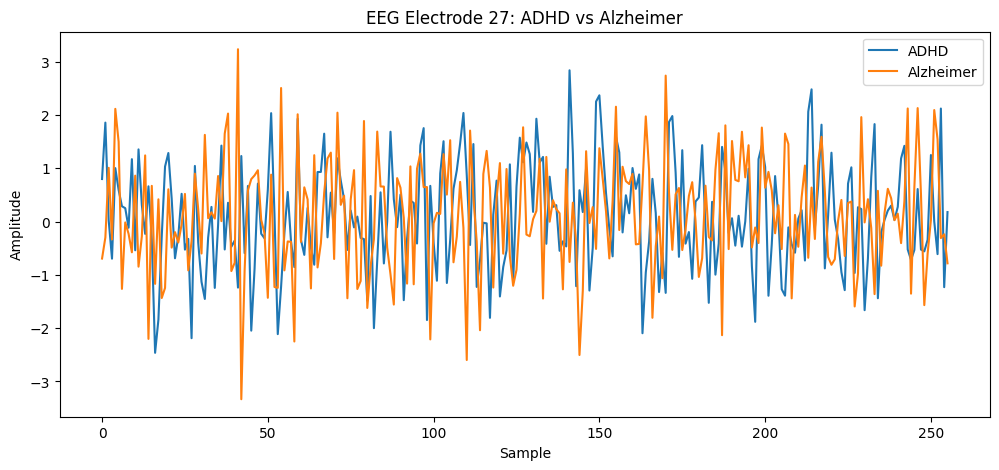

In [78]:
import matplotlib.pyplot as plt

# Pick one sample from two different classes
sample_1 = raw_df[raw_df["disorder/diagnosis"] == "ADHD"].iloc[0]
sample_2 = raw_df[raw_df["disorder/diagnosis"] == "Alzheimer"].iloc[0]

plt.figure(figsize=(12, 5))

plt.plot(sample_1["EEG_Electrode_27"], label="ADHD")
plt.plot(sample_2["EEG_Electrode_27"], label="Alzheimer")

plt.title("EEG Electrode 27: ADHD vs Alzheimer")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.show()

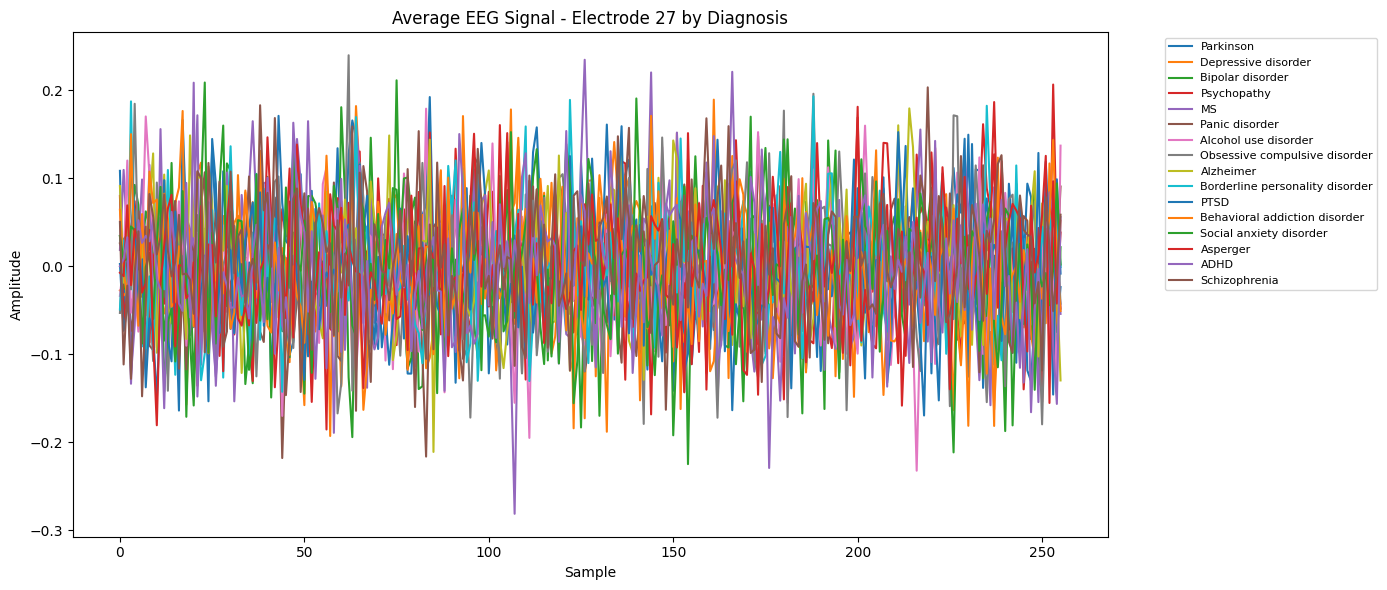

In [79]:
plt.figure(figsize=(14, 6))

diagnoses = raw_df["disorder/diagnosis"].unique()

for diagnosis in diagnoses:
    signals = raw_df[
        raw_df["disorder/diagnosis"] == diagnosis
    ]["EEG_Electrode_27"]

    # Convert all signals to a matrix
    signal_matrix = np.vstack(signals.values)

    # Average signal across all samples in this diagnosis
    mean_signal = signal_matrix.mean(axis=0)

    plt.plot(mean_signal, label=diagnosis)

plt.title("Average EEG Signal - Electrode 27 by Diagnosis")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

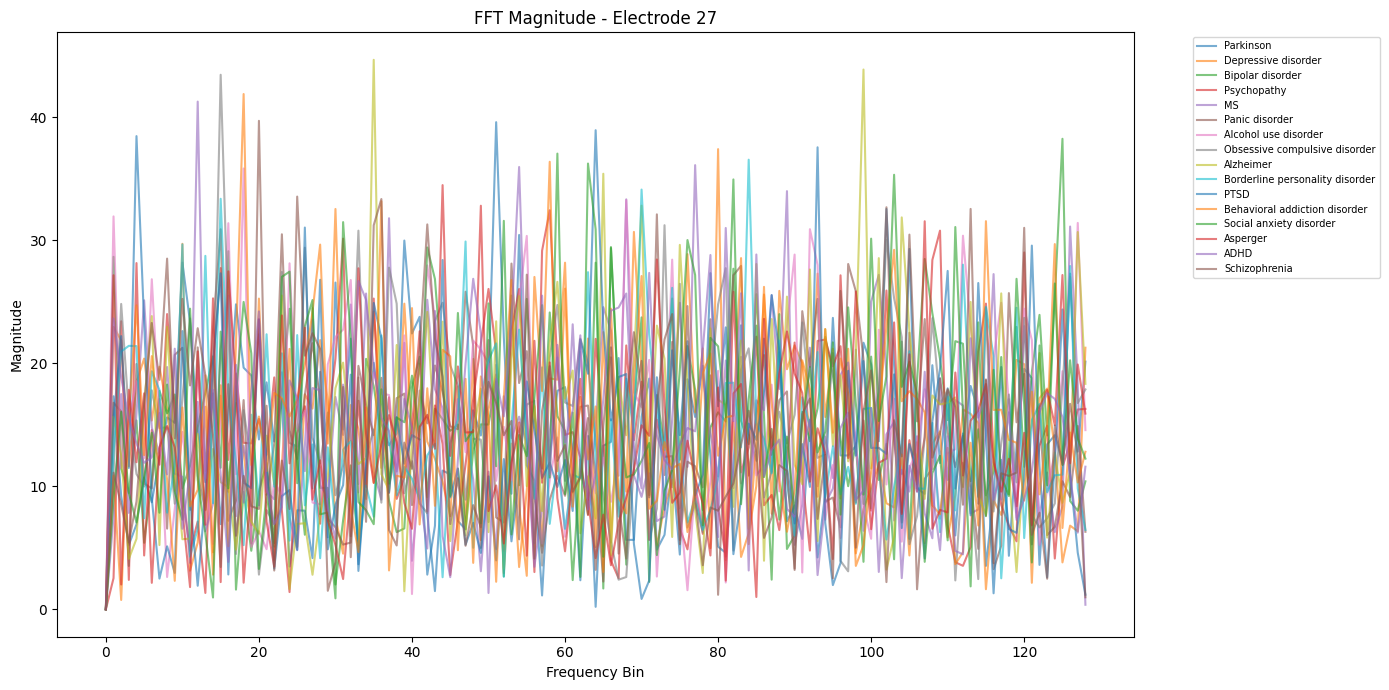

In [80]:
import numpy as np
import matplotlib.pyplot as plt

# Select one sample from each diagnosis
diagnoses = raw_df["disorder/diagnosis"].unique()

plt.figure(figsize=(14, 7))

for diagnosis in diagnoses:
    signal = raw_df[
        raw_df["disorder/diagnosis"] == diagnosis
    ]["EEG_Electrode_27"].iloc[0]

    signal = np.asarray(signal)

    # Remove DC component
    signal = signal - np.mean(signal)

    # FFT
    fft_values = np.fft.rfft(signal)
    magnitude = np.abs(fft_values)

    # Normalized frequency-bin index
    frequency_bins = np.arange(len(magnitude))

    plt.plot(
        frequency_bins,
        magnitude,
        alpha=0.6,
        label=diagnosis
    )

plt.title("FFT Magnitude - Electrode 27")
plt.xlabel("Frequency Bin")
plt.ylabel("Magnitude")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=7
)

plt.tight_layout()
plt.show()

In [81]:
# Average standard deviation of each electrode by diagnosis

std_results = []

for diagnosis, group in raw_df.groupby("disorder/diagnosis"):

    row = {"diagnosis": diagnosis}

    for col in eeg_columns:
        row[col] = np.mean([
            np.std(signal)
            for signal in group[col]
        ])

    std_results.append(row)

std_by_class = pd.DataFrame(std_results)

std_by_class = std_by_class.set_index("diagnosis")

print(std_by_class.round(3))

                                 EEG_Electrode_1  EEG_Electrode_2  \
diagnosis                                                           
ADHD                                       0.991            0.995   
Alcohol use disorder                       0.992            0.998   
Alzheimer                                  0.999            0.997   
Asperger                                   0.997            0.996   
Behavioral addiction disorder              0.997            0.998   
Bipolar disorder                           0.994            1.002   
Borderline personality disorder            0.994            0.993   
Depressive disorder                        0.998            0.993   
MS                                         0.994            0.995   
Obsessive compulsive disorder              0.996            0.998   
PTSD                                       0.995            0.991   
Panic disorder                             0.998            0.997   
Parkinson                         

In [82]:
# Check temporal structure of EEG signals

autocorr_results = []

for diagnosis, group in raw_df.groupby("disorder/diagnosis"):

    row = {"diagnosis": diagnosis}

    for col in eeg_columns:

        correlations = []

        for signal in group[col]:
            signal = np.asarray(signal)

            # Correlation between consecutive samples
            corr = np.corrcoef(
                signal[:-1],
                signal[1:]
            )[0, 1]

            correlations.append(corr)

        row[col] = np.mean(correlations)

    autocorr_results.append(row)

autocorr_by_class = pd.DataFrame(
    autocorr_results
).set_index("diagnosis")

print(autocorr_by_class.round(3))

                                 EEG_Electrode_1  EEG_Electrode_2  \
diagnosis                                                           
ADHD                                       0.002           -0.000   
Alcohol use disorder                      -0.006           -0.003   
Alzheimer                                 -0.004           -0.006   
Asperger                                  -0.011           -0.001   
Behavioral addiction disorder              0.003           -0.008   
Bipolar disorder                          -0.002           -0.004   
Borderline personality disorder           -0.005           -0.009   
Depressive disorder                       -0.002            0.004   
MS                                         0.001           -0.005   
Obsessive compulsive disorder             -0.002           -0.011   
PTSD                                       0.000           -0.003   
Panic disorder                             0.004           -0.014   
Parkinson                         

In [83]:
# Create raw EEG tensor

X_eeg = np.stack([
    np.stack(row[eeg_columns].values)
    for _, row in raw_df.iterrows()
])

print("Raw EEG shape:", X_eeg.shape)

Raw EEG shape: (3444, 32, 256)


In [84]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Encode the 16 diagnosis classes as numbers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(
    raw_df["disorder/diagnosis"]
)

print("Number of classes:", len(label_encoder.classes_))
print("Classes:", label_encoder.classes_)

# Split the raw EEG data
X_cnn_train, X_cnn_test, y_cnn_train, y_cnn_test = train_test_split(
    X_eeg,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining EEG shape:", X_cnn_train.shape)
print("Testing EEG shape:", X_cnn_test.shape)
print("Training labels shape:", y_cnn_train.shape)
print("Testing labels shape:", y_cnn_test.shape)

Number of classes: 16
Classes: ['ADHD' 'Alcohol use disorder' 'Alzheimer' 'Asperger'
 'Behavioral addiction disorder' 'Bipolar disorder'
 'Borderline personality disorder' 'Depressive disorder' 'MS'
 'Obsessive compulsive disorder' 'PTSD' 'Panic disorder' 'Parkinson'
 'Psychopathy' 'Schizophrenia' 'Social anxiety disorder']

Training EEG shape: (2755, 32, 256)
Testing EEG shape: (689, 32, 256)
Training labels shape: (2755,)
Testing labels shape: (689,)


In [85]:

# Check for missing or invalid values
print("Non-finite values:", np.size(X_eeg) - np.isfinite(X_eeg).sum())

# Change shape from (samples, electrodes, time)
# to (samples, time, electrodes)
X_cnn_train = np.transpose(X_cnn_train, (0, 2, 1))
X_cnn_test = np.transpose(X_cnn_test, (0, 2, 1))

print("Training shape:", X_cnn_train.shape)
print("Testing shape:", X_cnn_test.shape)

Non-finite values: 0
Training shape: (2755, 256, 32)
Testing shape: (689, 256, 32)


In [86]:
# Calculate mean and standard deviation from training data
channel_mean = X_cnn_train.mean(axis=(0, 1), keepdims=True)
channel_std = X_cnn_train.std(axis=(0, 1), keepdims=True)

# Prevent division by zero
channel_std[channel_std == 0] = 1

# Standardize training and testing data
X_cnn_train_scaled = (X_cnn_train - channel_mean) / channel_std
X_cnn_test_scaled = (X_cnn_test - channel_mean) / channel_std

print("Training data:", X_cnn_train_scaled.shape)
print("Testing data:", X_cnn_test_scaled.shape)
print("Training mean:", round(float(X_cnn_train_scaled.mean()), 4))
print("Training standard deviation:", round(float(X_cnn_train_scaled.std()), 4))

Training data: (2755, 256, 32)
Testing data: (689, 256, 32)
Training mean: 0.0
Training standard deviation: 1.0


In [119]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    BatchNormalization, GlobalAveragePooling1D,
    Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

# Build the CNN
model = Sequential([
    Input(shape=(256, 32)),

    Conv1D(32, kernel_size=7, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(64, kernel_size=5, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.4),

    Dense(16, activation="softmax")
])

# Configure training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_6 (Conv1D)           (None, 256, 32)           7200      
                                                                 
 batch_normalization_6 (Batc  (None, 256, 32)          128       
 hNormalization)                                                 
                                                                 
 max_pooling1d_4 (MaxPooling  (None, 128, 32)          0         
 1D)                                                             
                                                                 
 conv1d_7 (Conv1D)           (None, 128, 64)           10304     
                                                                 
 batch_normalization_7 (Batc  (None, 128, 64)          256       
 hNormalization)                                                 
                                                      

In [120]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_cnn_train_scaled,
    y_cnn_train,
    validation_split=0.15,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
74/74 [==============================] - 9s 80ms/step - loss: 2.7845 - accuracy: 0.0577 - val_loss: 2.7903 - val_accuracy: 0.0652
Epoch 2/50
74/74 [==============================] - 5s 71ms/step - loss: 2.6913 - accuracy: 0.1534 - val_loss: 2.7982 - val_accuracy: 0.0435
Epoch 3/50
74/74 [==============================] - 5s 65ms/step - loss: 2.6032 - accuracy: 0.2029 - val_loss: 2.8090 - val_accuracy: 0.0459
Epoch 4/50
74/74 [==============================] - 5s 71ms/step - loss: 2.4653 - accuracy: 0.2529 - val_loss: 2.8586 - val_accuracy: 0.0725
Epoch 5/50
74/74 [==============================] - 6s 79ms/step - loss: 2.2751 - accuracy: 0.3208 - val_loss: 2.9537 - val_accuracy: 0.0604
Epoch 6/50
74/74 [==============================] - 5s 67ms/step - loss: 2.0067 - accuracy: 0.4041 - val_loss: 3.4509 - val_accuracy: 0.0676
Epoch 7/50
74/74 [==============================] - 5s 70ms/step - loss: 1.6840 - accuracy: 0.5049 - val_loss: 3.5742 - val_accuracy: 0.0483
Epoch 8/50
74

In [123]:
import os

os.makedirs("models", exist_ok=True)

model.save("models/neurosense_cnn.keras")

print("Model saved successfully!")
print("Location:", os.path.abspath("models/neurosense_cnn.keras"))

Model saved successfully!
Location: c:\pythonfullstack\project\EEG PROJECT\DATA\models\neurosense_cnn.keras


In [124]:


np.savez(
    "models/neurosense_preprocessing.npz",
    channel_mean=channel_mean,
    channel_std=channel_std
)

print("Preprocessing parameters saved!")

Preprocessing parameters saved!


In [125]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: streamlit in c:\users\amrut\anaconda3\lib\site-packages (1.65.0)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 3.19.6
    Uninstalling protobuf-3.19.6:
      Successfully uninstalled protobuf-3.19.6



  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mysql-connector-python 8.0.33 requires protobuf<=3.20.3,>=3.11.0, but you have protobuf 7.36.2 which is incompatible.
tensorboard 2.10.1 requires protobuf<3.20,>=3.9.2, but you have protobuf 7.36.2 which is incompatible.
tensorflow 2.10.1 requires protobuf<3.20,>=3.9.2, but you have protobuf 7.36.2 which is incompatible.


In [126]:

# Find variables related to label encoding
print("Label-related variables:")

for name in globals():
    if "label" in name.lower() or "encoder" in name.lower():
        print(name)

# Check common label encoder variables
for name in ["label_encoder", "le", "encoder"]:
    if name in globals():
        obj = globals()[name]
        if hasattr(obj, "classes_"):
            print(f"\n{name} class order:")
            print(list(obj.classes_))


Label-related variables:
LabelEncoder
label_encoder
OneHotEncoder

label_encoder class order:
['ADHD', 'Alcohol use disorder', 'Alzheimer', 'Asperger', 'Behavioral addiction disorder', 'Bipolar disorder', 'Borderline personality disorder', 'Depressive disorder', 'MS', 'Obsessive compulsive disorder', 'PTSD', 'Panic disorder', 'Parkinson', 'Psychopathy', 'Schizophrenia', 'Social anxiety disorder']


In [127]:

import json
from pathlib import Path

# Folder where your saved CNN model is located
models_dir = Path(
    r"C:\pythonfullstack\project\EEG PROJECT\DATA\models"
)

models_dir.mkdir(parents=True, exist_ok=True)

# Save the exact class order from your training label encoder
class_names = label_encoder.classes_.tolist()

file_path = models_dir / "class_names.json"

with open(file_path, "w", encoding="utf-8") as f:
    json.dump(class_names, f, indent=4)

print("Class mapping saved successfully!")
print("File:", file_path)
print("Number of classes:", len(class_names))
print("Class order:", class_names)


Class mapping saved successfully!
File: C:\pythonfullstack\project\EEG PROJECT\DATA\models\class_names.json
Number of classes: 16
Class order: ['ADHD', 'Alcohol use disorder', 'Alzheimer', 'Asperger', 'Behavioral addiction disorder', 'Bipolar disorder', 'Borderline personality disorder', 'Depressive disorder', 'MS', 'Obsessive compulsive disorder', 'PTSD', 'Panic disorder', 'Parkinson', 'Psychopathy', 'Schizophrenia', 'Social anxiety disorder']
